# Geographically Weighted Spatial Regression (GWSR)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
from matplotlib_scalebar.scalebar import ScaleBar
from scipy.stats import rankdata
from scipy.stats import norm
from geo_northarrow import add_north_arrow
from mpl_toolkits.axes_grid1 import make_axes_locatable


In [2]:
# Load the dataset
# Read the GeoPackage file containing the catchment data
gdf = gpd.read_file("/home/edier/GoogleDrive/INVESTIGACION/PAPERS/ELABORACION/PAPER_SAR/Data/df_catchments_kmeans.gpkg")
gdf.info()  # Display basic information about the GeoDataFrame

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 526 entries, 0 to 525
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   id                   526 non-null    int64   
 1   Nombre               526 non-null    object  
 2   ID_CUENCA            526 non-null    float64 
 3   cuenca               526 non-null    object  
 4   area                 526 non-null    int64   
 5   elev_mean            526 non-null    float64 
 6   elev_median          526 non-null    float64 
 7   rel_mean             526 non-null    float64 
 8   rel_median           526 non-null    float64 
 9   rainfallAnnual_mean  526 non-null    float64 
 10  Densidad             526 non-null    float64 
 11  hypso_inte           526 non-null    float64 
 12  slope_mean           526 non-null    float64 
 13  kmeans               526 non-null    object  
 14  RainfallDaysmean     526 non-null    float64 
 15  RainfallDaysmed

In [3]:
# Calculate landslide density as landslides per unit area
gdf['y_log'] = np.log(gdf['lands_rec'] + 1)
g_y = gdf['y_log'].values.reshape(-1, 1)

# Extract predictor variables for GWR model
predictor_vars = gdf[['area', 'elev_mean', 'rel_mean']]

# Standardize continuous variables 'elev_mean' and 'slope_mean'
scaler = StandardScaler()
g_X_num = scaler.fit_transform(gdf[['area', 'elev_mean', 'rel_mean']])

In [4]:
# Extract centroid coordinates of each catchment for spatial modeling
u = gdf.centroid.x
v = gdf.centroid.y
g_coords = list(zip(u, v))

In [9]:
# Calibrate GWR model
# Select optimal bandwidth for GWR model using coordinates, response, and predictors
gwr_selector = Sel_BW(g_coords, g_y, g_X_num)
gwr_bw = gwr_selector.search(bw_min=4)  # Perform bandwidth search starting from a minimum of 10
print(gwr_bw)  # Print the selected bandwidth


41.0


In [16]:
# Fit GWR model using the calculated bandwidth
gwr_results = GWR(g_coords, g_y, g_X_num, gwr_bw).fit()

# Handle potential divide by zero warning
with np.errstate(divide='ignore', invalid='ignore'):
    gdf['R2_gwr_bw'] = gwr_results.localR2

In [17]:
np.float = float 
gwr_results.summary()

Model type                                                         Gaussian
Number of observations:                                                 526
Number of covariates:                                                     5

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                         611555.627
Log-likelihood:                                                   -2602.737
AIC:                                                               5215.473
AICc:                                                              5217.635
BIC:                                                             608291.405
R2:                                                                   0.311
Adj. R2:                                                              0.305

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [26]:
# Assuming g_coords, g_y, and g_X_num are defined, representing the coordinates, response, and predictors

# Bandwidth values to test
bandwidths = [10, 50, 200, 500]

# Mapping of covariates to LaTeX-friendly variable names
var_map = {
    'constant': 'Const',
    'area': '$A$',
    'elev_mean': '$E$',
    'rel_mean': '$H$'
}

# Variables (covariates) used in the models, include 'constant'
variables = ['constant', 'area', 'elev_mean', 'rel_mean']

# Initialize a DataFrame to store the summary statistics (min, mean, max) for each covariate and bandwidth
results_df = pd.DataFrame(index=[var_map[var] for var in variables], columns=[f"BW {bw}" for bw in bandwidths])

# Initialize dictionaries to store Adj R² and AIC values
adj_r2_dict = {}
aic_dict = {}

# Loop through the bandwidths and fit the GWR model for each
for bw in bandwidths:
    # Fit the GWR model
    gwr_results = GWR(g_coords, g_y, g_X_num, bw).fit()

    # Store Adj R² and AIC for each bandwidth
    adj_r2_dict[f"BW {bw}"] = f"{gwr_results.adj_R2:.3f}"
    aic_dict[f"BW {bw}"] = f"{gwr_results.aic:.3f}"

    # For each variable, extract the min, mean, and max values of the coefficients
    for var_idx, var in enumerate(variables):
        coef_mean = gwr_results.params[:, var_idx].mean()
        coef_min = gwr_results.params[:, var_idx].min()
        coef_max = gwr_results.params[:, var_idx].max()
        
        # Store the (min, mean, max) as a formatted string with the mean in bold and min/max in smaller font size
        coef_str = f"{{\\scriptsize {coef_min:.3f}}}, \\textbf{{{coef_mean:.3f}}}, {{\\scriptsize {coef_max:.3f}}}"
        
        # Update the DataFrame with the formatted string
        results_df.loc[var_map[var], f"BW {bw}"] = coef_str

# Add rows for Adj R² and AIC at the bottom of the table
results_df.loc['Adj R²'] = adj_r2_dict
results_df.loc['AIC'] = aic_dict

# Generate the LaTeX table with bold headers automatically
latex_table = results_df.to_latex(escape=False, column_format="l" + "c" * len(bandwidths), index=True, header=True)

# Insert \midrule before the Adj R² row and keep \bottomrule after the AIC row
latex_table = latex_table.replace("Adj R²", "\\midrule\nAdj R²")

# Display the LaTeX table
print(latex_table)

\begin{tabular}{lcccc}
\toprule
 & BW 10 & BW 50 & BW 200 & BW 500 \\
\midrule
Const & {\scriptsize -31.793}, \textbf{2.244}, {\scriptsize 16.443} & {\scriptsize -1.155}, \textbf{1.957}, {\scriptsize 5.021} & {\scriptsize 1.482}, \textbf{1.996}, {\scriptsize 2.762} & {\scriptsize 1.697}, \textbf{1.908}, {\scriptsize 2.063} \\
$A$ & {\scriptsize -6.346}, \textbf{0.927}, {\scriptsize 12.990} & {\scriptsize -0.026}, \textbf{0.656}, {\scriptsize 1.404} & {\scriptsize 0.276}, \textbf{0.616}, {\scriptsize 0.780} & {\scriptsize 0.518}, \textbf{0.606}, {\scriptsize 0.682} \\
$E$ & {\scriptsize -32.985}, \textbf{0.368}, {\scriptsize 11.871} & {\scriptsize -2.178}, \textbf{0.404}, {\scriptsize 2.828} & {\scriptsize -0.351}, \textbf{0.455}, {\scriptsize 0.953} & {\scriptsize 0.336}, \textbf{0.489}, {\scriptsize 0.687} \\
$H$ & {\scriptsize -5.951}, \textbf{0.526}, {\scriptsize 14.452} & {\scriptsize -0.816}, \textbf{0.518}, {\scriptsize 1.992} & {\scriptsize 0.209}, \textbf{0.657}, {\scriptsize 1

In [119]:
#Prepare GWR results for mapping
gdf['gwr_intercept_36'] = gwr_results.params[:,0]
gdf['gwr_elev_36'] = gwr_results.params[:,1]
gdf['gwr_slope_36'] = gwr_results.params[:,2]


#Obtain t-vals filtered based on multiple testing correction
gwr_filtered_t = gwr_results.filter_tvals()

<Axes: >

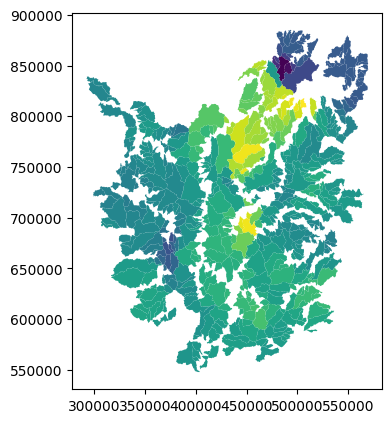

In [120]:
gdf.plot(column='gwr_intercept_36',figsize=(4,6))

<Axes: >

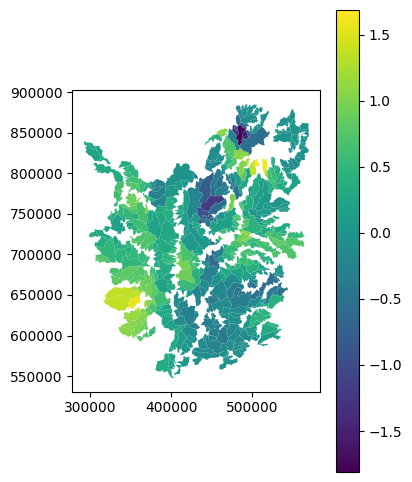

In [121]:
gdf.plot(column='gwr_elev_36',figsize=(4,6),legend=True)

<Axes: >

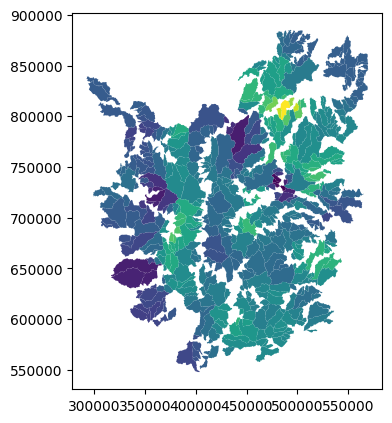

In [122]:
gdf.plot(column='gwr_slope_36',figsize=(4,6))

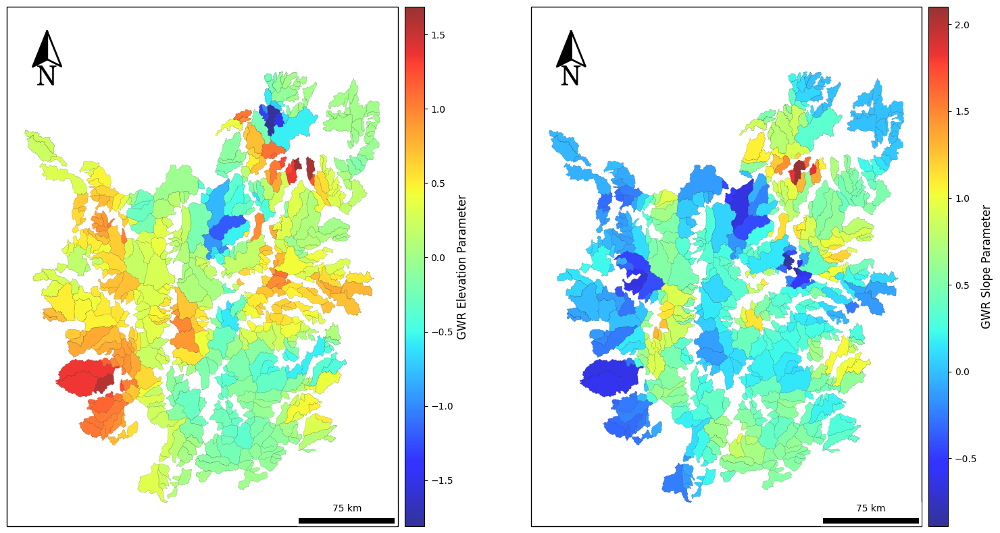

In [148]:
# Create a figure with two subplots in 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
cmap = plt.cm.jet

# Plot GWR elev parameter in the first subplot
elev_plot = gdf.plot(column='gwr_elev_36', ax=axes[0], legend=False, cmap=cmap, edgecolor='black', linewidth=0.1, alpha=0.8)
axes[0].set_axis_off()
axes[0].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='black', lw=1, transform=axes[0].transAxes, clip_on=False))

# Add north arrow and scale bar to the first subplot
add_north_arrow(axes[0], scale=.75, xlim_pos=.1025, ylim_pos=.965, color='#000', text_scaler=4, text_yT=-1.25)
scalebar = ScaleBar(1, "m", location='lower right', scale_loc='top', length_fraction=0.25, font_properties={"size": 10})
axes[0].add_artist(scalebar)

# Create a colorbar for the first figure
divider0 = make_axes_locatable(axes[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.1)
cbar0 = plt.colorbar(elev_plot.collections[0], cax=cax0, cmap=cmap)
cbar0.set_label("GWR Elevation Parameter", fontsize=12)
cbar0.outline.set_edgecolor('black')

# Plot GWR slope parameter in the second subplot
slope_plot = gdf.plot(column='gwr_slope_36', ax=axes[1], legend=False, cmap=cmap, edgecolor='black', linewidth=0.1, alpha=0.8)
axes[1].set_axis_off()
axes[1].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='black', lw=1, transform=axes[1].transAxes, clip_on=False))

# Add north arrow and scale bar to the second subplot
add_north_arrow(axes[1], scale=.75, xlim_pos=.1025, ylim_pos=.965, color='#000', text_scaler=4, text_yT=-1.25)
scalebar = ScaleBar(1, "m", location='lower right', scale_loc='top', length_fraction=0.25, font_properties={"size": 10})
axes[1].add_artist(scalebar)

# Create a colorbar for the second figure
divider1 = make_axes_locatable(axes[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.1)
cbar1 = plt.colorbar(slope_plot.collections[0], cax=cax1, cmap=cmap)
cbar1.set_label("GWR Slope Parameter", fontsize=12)
cbar1.outline.set_edgecolor('black')

plt.tight_layout()
plt.savefig('G:/My Drive/INVESTIGACION/PAPERS/ELABORACION/PAPER_SAR/Figures/gwr_results_adjusted.png', dpi=500, bbox_inches='tight')
plt.show()

## Multiscale Geographically Weighted Regression (MGWR)

In [5]:
#Calibrate MGWR model
mgwr_selector = Sel_BW(g_coords, g_y, g_X_num, multi=True)
mgwr_bw = mgwr_selector.search(multi_bw_min=[4])
print(mgwr_bw)
mgwr_results = MGWR(g_coords, g_y, g_X_num, mgwr_selector).fit()

/home/edier/miniconda3/envs/ml/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Backfitting:  22%|██████▏                      | 43/200 [01:55<07:00,  2.68s/it]


[ 22. 124. 302. 504.]


Inference: 100%|███████████████████████████████| 1/1 [00:00<00:00, 17050.02it/s]


Model type                                                         Gaussian
Number of observations:                                                 526
Number of covariates:                                                     4

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            645.849
Log-likelihood:                                                    -800.346
AIC:                                                               1608.693
AICc:                                                              1610.808
BIC:                                                              -2624.638
R2:                                                                   0.499
Adj. R2:                                                              0.497

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

C:\Users\edier\AppData\Local\Temp\ipykernel_12816\1497169667.py:7: UserWarning: The figure layout has changed to tight
  plt.gcf().tight_layout(pad=1.0)


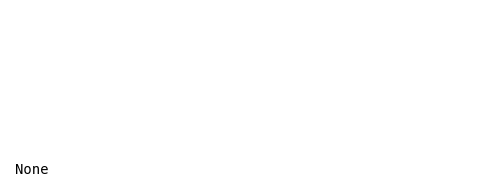

In [10]:
#mgwr_results.summary()
np.float = float 
plt.rc("figure", figsize=(5, 2))
plt.text(0.01, 0.05, str(mgwr_results.summary()), {"fontsize": 10}, fontproperties="monospace")
plt.axis("off")
plt.tight_layout()
plt.gcf().tight_layout(pad=1.0)
plt.savefig('G:/My Drive/INVESTIGACION/POSDOC/Figuras/mgwr.png', dpi=300, bbox_inches='tight')

In [6]:
#Prepare MGWR results for mapping

#Add MGWR parameters to GeoDataframe
gdf['mgwr_intercept'] = mgwr_results.params[:,0]
gdf['mgwr_A'] = mgwr_results.params[:,1]
gdf['mgwr_E'] = mgwr_results.params[:,2]
gdf['mgwr_H'] = mgwr_results.params[:,3]

#Obtain t-vals filtered based on multiple testing correction
mgwr_filtered_t = mgwr_results.filter_tvals()

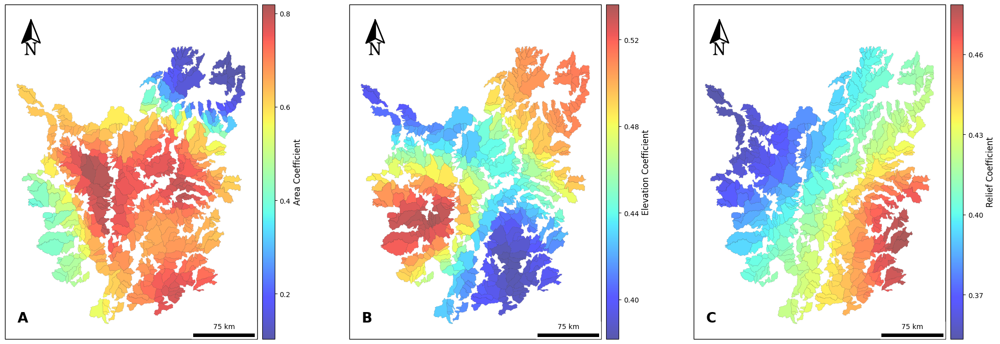

In [10]:
# Create a figure with three subplots in 1 row and 3 columns
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(21, 7))  # Adjusted for 3 columns
ax0 = axes[0]
ax1 = axes[1]
ax2 = axes[2]  # New axis for the third plot
cmap = plt.cm.jet

# Plot MGWR Area parameter in the first subplot
gdf.plot('mgwr_A', cmap=cmap, ax=ax0, edgecolor='black', linewidth=0.1, alpha=0.65)
ax0.set_axis_off()
axes[0].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='black', lw=1, transform=axes[0].transAxes, clip_on=False))

# Add north arrow and scale bar to the first subplot
add_north_arrow(ax0, scale=.75, xlim_pos=.1025, ylim_pos=.965, color='#000', text_scaler=4, text_yT=-1.25)
scalebar0 = ScaleBar(1, "m", location="lower right", scale_loc="top", length_fraction=0.25, font_properties={"size": 10})
ax0.add_artist(scalebar0)
ax0.text(0.05, 0.05, "A", transform=ax0.transAxes, fontsize=20, fontweight='bold')

# Create a colorbar for the first figure with specific ticks at 0.2, 0.4, 0.6, 0.8
divider0 = make_axes_locatable(ax0)
cax0 = divider0.append_axes("right", size="5%", pad=0.1)
ticks_area = [0.2, 0.4, 0.6, 0.8]
cbar0 = plt.colorbar(ax0.collections[0], cax=cax0, ticks=ticks_area)
cbar0.set_label("Area Coefficient", fontsize=12)

# Plot MGWR Elevation parameter in the second subplot
gdf.plot('mgwr_E', cmap=cmap, ax=ax1, edgecolor='black', linewidth=0.1, alpha=0.65)
ax1.set_axis_off()
axes[1].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='black', lw=1, transform=axes[1].transAxes, clip_on=False))

# Add north arrow and scale bar to the second subplot
add_north_arrow(ax1, scale=.75, xlim_pos=.1025, ylim_pos=.965, color='#000', text_scaler=4, text_yT=-1.25)
scalebar1 = ScaleBar(1, "m", location="lower right", scale_loc="top", length_fraction=0.25, font_properties={"size": 10})
ax1.add_artist(scalebar1)
ax1.text(0.05, 0.05, "B", transform=ax1.transAxes, fontsize=20, fontweight='bold')

# Create a colorbar for the second figure with specific ticks at 0.4, 0.44, 0.48, 0.52
divider1 = make_axes_locatable(ax1)
cax1 = divider1.append_axes("right", size="5%", pad=0.1)
ticks_elevation = [0.4, 0.44, 0.48, 0.52]
cbar1 = plt.colorbar(ax1.collections[0], cax=cax1, ticks=ticks_elevation)
cbar1.set_label("Elevation Coefficient", fontsize=12)

# Plot MGWR Relief parameter in the third subplot
gdf.plot('mgwr_H', cmap=cmap, ax=ax2, edgecolor='black', linewidth=0.1, alpha=0.65)
ax2.set_axis_off()
axes[2].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, edgecolor='black', lw=1, transform=axes[2].transAxes, clip_on=False))

# Add north arrow and scale bar to the third subplot
add_north_arrow(ax2, scale=.75, xlim_pos=.1025, ylim_pos=.965, color='#000', text_scaler=4, text_yT=-1.25)
scalebar2 = ScaleBar(1, "m", location="lower right", scale_loc="top", length_fraction=0.25, font_properties={"size": 10})
ax2.add_artist(scalebar2)
ax2.text(0.05, 0.05, "C", transform=ax2.transAxes, fontsize=20, fontweight='bold')

# Create a colorbar for the third figure with specific ticks at 0.35, 0.40, 0.45, 0.50
divider2 = make_axes_locatable(ax2)
cax2 = divider2.append_axes("right", size="5%", pad=0.1)
ticks_relief = [0.37, 0.40, 0.43, 0.46]
cbar2 = plt.colorbar(ax2.collections[0], cax=cax2, ticks=ticks_relief)
cbar2.set_label("Relief Coefficient", fontsize=12)

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('/home/edier/GoogleDrive/INVESTIGACION/PAPERS/ELABORACION/PAPER_SAR/Figures/figFinal/Fig12.png', dpi=500, bbox_inches='tight')
plt.show()

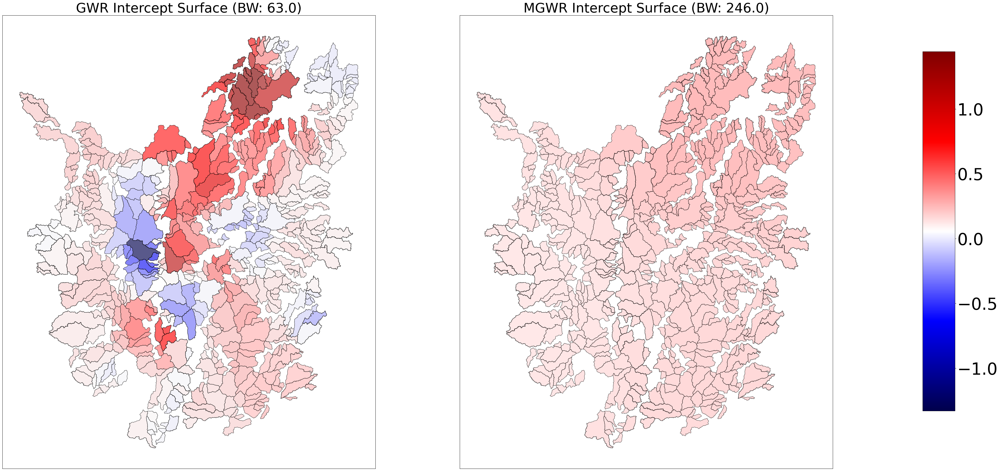

In [106]:
from mgwr.utils import shift_colormap, truncate_colormap

#Prep plot and add axes
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Intercept Surface (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Intercept Surface (BW: ' + str(mgwr_bw[0]) +')', fontsize=40)

#Set color map
cmap = plt.cm.seismic

#Find min and max values of the two combined datasets
gwr_min = gdf['gwr_intercept'].min()
gwr_max = gdf['gwr_intercept'].max()
mgwr_min = gdf['mgwr_intercept'].min()
mgwr_max = gdf['mgwr_intercept'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

#If all values are negative use the negative half of the colormap
if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
#If all values are positive use the positive half of the colormap
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)
#Otherwise, there are positive and negative values so the colormap so zero is the midpoint
#else:
    #cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)

#Create scalar mappable for colorbar and stretch colormap across range of data values
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

#Plot GWR parameters
gdf.plot('gwr_intercept', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#If there are insignificnt parameters plot gray polygons over them
if (gwr_filtered_t[:,0] == 0).any():
    gdf[gwr_filtered_t[:,0] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

#Plot MGWR parameters
gdf.plot('mgwr_intercept', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#If there are insignificnt parameters plot gray polygons over them
if (mgwr_filtered_t[:,0] == 0).any():
    gdf[mgwr_filtered_t[:,0] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
 
#Set figure options and plot 
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)


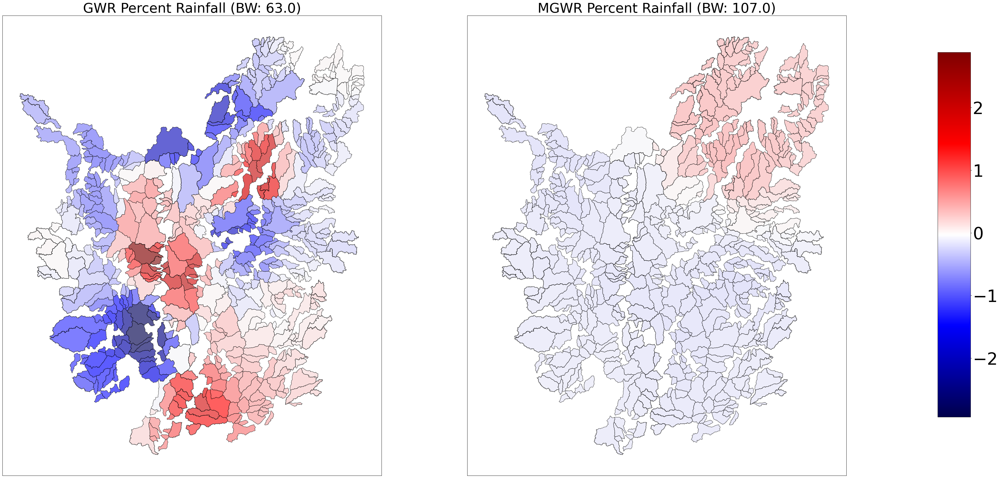

In [108]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Percent Rainfall (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Percent Rainfall (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.seismic
gwr_min = gdf['gwr_rainfallAnnual'].min()
gwr_max = gdf['gwr_rainfallAnnual'].max()
mgwr_min = gdf['mgwr_rainfallAnnual'].min()
mgwr_max = gdf['mgwr_rainfallAnnual'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

#cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)
    
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

gdf.plot('gwr_rainfallAnnual', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (gwr_filtered_t[:,1] == 0).any():
    gdf[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

gdf.plot('mgwr_rainfallAnnual', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (mgwr_filtered_t[:,1] == 0).any():
    gdf[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
    
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)


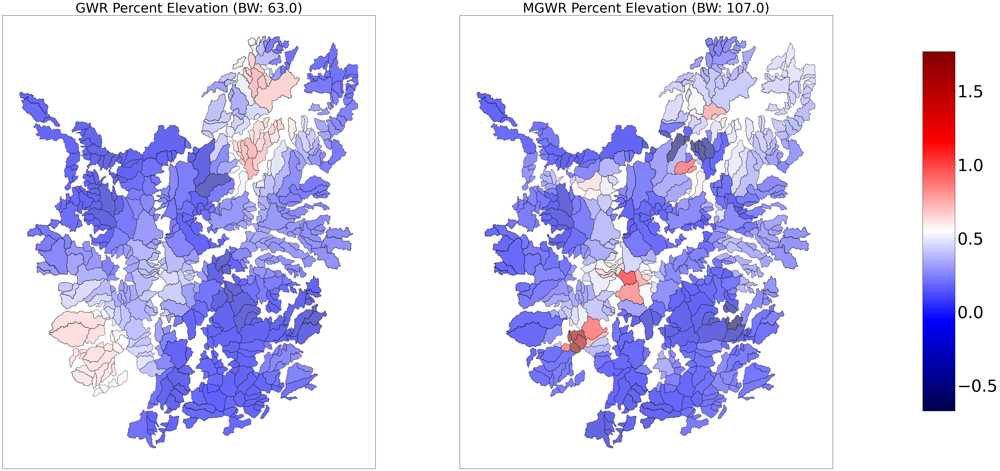

In [110]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Percent Elevation (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Percent Elevation (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.seismic
gwr_min = gdf['gwr_elev'].min()
gwr_max = gdf['gwr_elev'].max()
mgwr_min = gdf['mgwr_elevation'].min()
mgwr_max = gdf['mgwr_elevation'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

#cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)
    
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

gdf.plot('gwr_elev', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (gwr_filtered_t[:,1] == 0).any():
    gdf[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

gdf.plot('mgwr_elevation', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (mgwr_filtered_t[:,1] == 0).any():
    gdf[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
    
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)
plt.savefig('G:/My Drive/INVESTIGACION/POSDOC/Figuras2/GWSR_elevation.png', dpi=500, bbox_inches='tight')

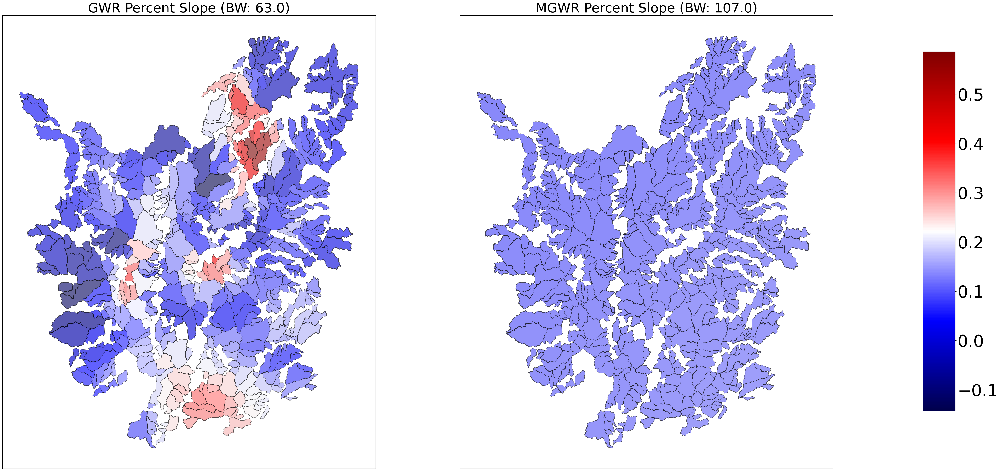

In [111]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(45,20))
ax0 = axes[0]
ax0.set_title('GWR Percent Slope (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
ax1.set_title('MGWR Percent Slope (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.seismic
gwr_min = gdf['gwr_slope'].min()
gwr_max = gdf['gwr_slope'].max()
mgwr_min = gdf['mgwr_slope'].min()
mgwr_max = gdf['mgwr_slope'].max()
vmin = np.min([gwr_min, mgwr_min])
vmax = np.max([gwr_max, mgwr_max])

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

#cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)
    
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

gdf.plot('gwr_slope', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (gwr_filtered_t[:,1] == 0).any():
    gdf[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

gdf.plot('mgwr_slope', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
if (mgwr_filtered_t[:,1] == 0).any():
    gdf[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
    
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.get_xaxis().set_visible(False)
ax0.get_yaxis().set_visible(False)
ax1.get_xaxis().set_visible(False)
ax1.get_yaxis().set_visible(False)
plt.savefig('G:/My Drive/INVESTIGACION/POSDOC/Figuras/GWSR_slope.png', dpi=500, bbox_inches='tight')

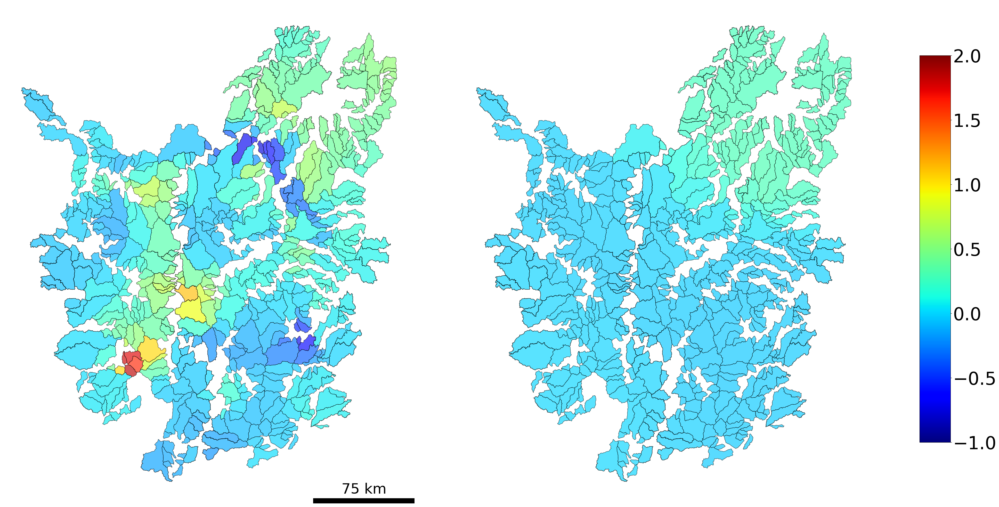

In [317]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(40,20))
ax0 = axes[0]
#ax0.set_title('GWR Percent Slope (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
#ax1.set_title('MGWR Percent Slope (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.jet
vmin = -1
vmax = 2

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

#cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)
    
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

gdf.plot('mgwr_elevation', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#if (gwr_filtered_t[:,1] == 0).any():
    #gdf[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

gdf.plot('mgwr_RainfallDays', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#if (mgwr_filtered_t[:,1] == 0).any():
    #gdf[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
scalebar = ScaleBar(1,"m",location="lower right",scale_loc="top",length_fraction=0.25,font_properties={"size": 40})
ax0.add_artist(scalebar)     
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.set_axis_off()
ax1.set_axis_off()
plt.savefig('G:/My Drive/INVESTIGACION/POSDOC/Figuras2/mgwr_173_16.png', dpi=500, bbox_inches='tight')

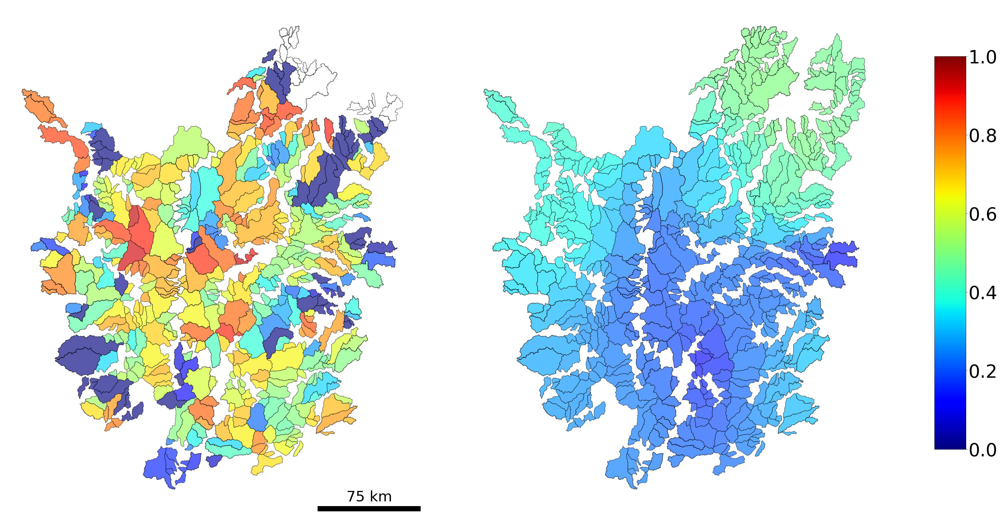

In [316]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(40,20))
ax0 = axes[0]
#ax0.set_title('GWR Percent Slope (BW: ' + str(gwr_bw) +')', fontsize=40)
ax1 = axes[1]
#ax1.set_title('MGWR Percent Slope (BW: ' + str(mgwr_bw[1]) +')', fontsize=40)
cmap = plt.cm.jet
vmin = 0
vmax = 1

if (vmin < 0) & (vmax < 0):
    cmap = truncate_colormap(cmap, 0.0, 0.5)
elif (vmin > 0) & (vmax > 0):
    cmap = truncate_colormap(cmap, 0.5, 1.0)

#cmap = shift_colormap(cmap, start=0.0, midpoint=1 - vmax/(vmax + abs(vmin)), stop=1.)
    
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=vmin, vmax=vmax))

gdf.plot('R2_16', cmap=sm.cmap, ax=ax0, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#if (gwr_filtered_t[:,1] == 0).any():
    #gdf[gwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax0, **{'edgecolor':'black'})

gdf.plot('R2_173', cmap=sm.cmap, ax=ax1, vmin=vmin, vmax=vmax, **{'edgecolor':'black', 'alpha':.65})
#if (mgwr_filtered_t[:,1] == 0).any():
    #gdf[mgwr_filtered_t[:,1] == 0].plot(color='lightgrey', alpha=0.1,ax=ax1, **{'edgecolor':'black'})
scalebar = ScaleBar(1,"m",location="lower right",scale_loc="top",length_fraction=0.25,font_properties={"size": 40})
ax0.add_artist(scalebar)     
fig.tight_layout()    
fig.subplots_adjust(right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.03, 0.75])
sm._A = []
cbar = fig.colorbar(sm, cax=cax)
cbar.ax.tick_params(labelsize=50) 
ax0.set_axis_off()
ax1.set_axis_off()
plt.savefig('G:/My Drive/INVESTIGACION/POSDOC/Figuras2/R2_16_173.png', dpi=500, bbox_inches='tight')

In [241]:
#Visualizing hypothesis tests for significance of parameter~estimates
#Manually set bandwidth to 107 and fit
gwr_model = GWR(g_coords, g_y, g_X, 107)
gwr_results = gwr_model.fit()

#default is 1000 iterations
p_vals_1000 = gwr_results.spatial_variability(gwr_selector)
print(p_vals_1000)



[0.    0.    0.    0.    0.001]


In [298]:
#Visualizing hypothesis tests for significance of parameter~estimates
#Manually set bandwidth to 107 and fit
gwr_model = GWR(g_coords, g_y, g_X, 16)
gwr_results = gwr_model.fit()

#default is 1000 iterations
p_vals_1000 = gwr_results.spatial_variability(gwr_selector)
print(p_vals_1000)

[0. 0. 0. 0.]


In [ ]:
# Out-of-sample prediction using~GWR
#Split data into calibration and prediction sets
sample = np.random.choice(range(159), 10)
mask = np.ones_like(g_y, dtype = bool).flatten()
mask[sample] = False
cal_coords = np.array(g_coords)[mask]
cal_y = g_y[mask]
cal_X = g_X[mask]
pred_coords = np.array(g_coords)[~mask]
pred_y = g_y[~mask]
 pred_X = g_X[~mask]

#Calibrate GWR model
gwr_selector = Sel_BW(cal_coords, cal_y, cal_X)
gwr_bw = gwr_selector.search(bw_min = 2)
print(gwr_bw)

model = GWR(cal_coords, cal_y, cal_X, gwr_bw)
gwr_results = model.fit()

#Make predictions
pred_results = model.predict(pred_coords, pred_X)

#Check correlation between known and predicted values
corr = np.corrcoef(pred_results.predictions.flatten(),
                 pred_y.flatten())[0][1]
print(corr)


In [ ]:
#Example of manual bandwidth selection in~MGWR
#Apply the same bandwidth to all variables
mgwr_selector = Sel_BW(b_coords, b_y, b_X, multi = True)
mgwr_bw = mgwr_selector.search(multi_bw_min = [500],multi_bw_max = [500])
print(mgwr_bw)
mgwr_results = MGWR(b_coords, b_y, b_X, mgwr_selector).fit()

#Unique manual bandwidths
mgwr_selector = Sel_BW(b_coords, b_y, b_X, multi = True)
mgwr_bw = mgwr_selector.search(multi_bw_min = [150, 500, 750, 1000],multi_bw_max = [150, 500, 750, 1000])
print(mgwr_bw)
mgwr_results = MGWR(b_coords, b_y, b_X, mgwr_selector).fit()